### **1. IMPORT LIBRARY**

In [220]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from scipy.stats import boxcox, jarque_bera
from scipy.special import inv_boxcox
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error, mean_absolute_error

import itertools
import warnings
warnings.filterwarnings("ignore")

# Setting visualisasi
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

print("Library berhasil diimpor.")

Library berhasil diimpor.


### **2. INPUT DATASET**

In [221]:
# Memuat dataset
df = pd.read_excel('data_kereta.xlsx', parse_dates=['Tanggal'])
df = df.sort_values('Tanggal').reset_index(drop=True)

print("Dataset berhasil dimuat")
print(f"Jumlah baris   : {df.shape[0]}")
print(f"Jumlah kolom   : {df.shape[1]}")
print(f"Kolom          : {df.columns.tolist()}")
print(f"Rentang waktu  : {df['Tanggal'].min().strftime('%Y-%m')} s.d. {df['Tanggal'].max().strftime('%Y-%m')}")
df.head(12)

Dataset berhasil dimuat
Jumlah baris   : 120
Jumlah kolom   : 5
Kolom          : ['Tanggal', 'Penumpang', 'Dummy_Covid', 'Inflasi', 'Hari_Libur']
Rentang waktu  : 2016-01 s.d. 2025-12


,Tanggal,Penumpang,Dummy_Covid,Inflasi,Hari_Libur
0,2016-01-01,28358000,0,0.51,11
1,2016-02-01,26510000,0,-0.09,9
2,2016-03-01,28617000,0,0.19,10
3,2016-04-01,28435000,0,-0.45,9
4,2016-05-01,30703000,0,0.24,11
5,2016-06-01,29159000,0,0.66,8
6,2016-07-01,28831000,0,0.69,15
7,2016-08-01,29588000,0,-0.02,9
8,2016-09-01,29516000,0,0.22,9
9,2016-10-01,30263000,0,0.14,10


### **3. DATA PREPROCESSING**

In [222]:
# Cek data hilang dan tipe data
print("Jumlah data hilang per kolom:")
print(df.isnull().sum())
print("\nTipe data:")
print(df.dtypes)

# Set index sebagai datetime
df = df.set_index('Tanggal')
df.index = pd.DatetimeIndex(df.index).to_period('M').to_timestamp()
df.index.freq = 'MS'

print(f"\nIndex diatur sebagai datetime bulanan (freq='MS'): {df.index[0].strftime('%Y-%m')} s.d. {df.index[-1].strftime('%Y-%m')}")
df.head()

Jumlah data hilang per kolom:
Tanggal        0
Penumpang      0
Dummy_Covid    0
Inflasi        0
Hari_Libur     0
dtype: int64

Tipe data:
Tanggal        datetime64[us]
Penumpang               int64
Dummy_Covid             int64
Inflasi               float64
Hari_Libur              int64
dtype: object

Index diatur sebagai datetime bulanan (freq='MS'): 2016-01 s.d. 2025-12


,Penumpang,Dummy_Covid,Inflasi,Hari_Libur
Tanggal,,,,
2016-01-01,28358000,0,0.51,11
2016-02-01,26510000,0,-0.09,9
2016-03-01,28617000,0,0.19,10
2016-04-01,28435000,0,-0.45,9
2016-05-01,30703000,0,0.24,11


### **4. SPLIT DATA**

In [223]:
SKALA = 1_000_000
df['Penumpang_juta'] = df['Penumpang'] / SKALA

TARGET_COL = 'Penumpang_juta'
EXOGENOUS_COLS = ['Dummy_Covid', 'Inflasi', 'Hari_Libur']

n_total = len(df)
n_train = int(np.floor(n_total * 0.8))
n_test = n_total - n_train

df_train = df.iloc[:n_train].copy()
df_test = df.iloc[n_train:].copy()

y_train, y_test = df_train[TARGET_COL], df_test[TARGET_COL]
X_train, X_test = df_train[EXOGENOUS_COLS], df_test[EXOGENOUS_COLS]

print(f"Total observasi     : {n_total}")
print(f"Data latih (80%)    : {n_train} observasi  ({df_train.index[0].strftime('%Y-%m')} s.d. {df_train.index[-1].strftime('%Y-%m')})")
print(f"Data uji   (20%)    : {n_test} observasi  ({df_test.index[0].strftime('%Y-%m')} s.d. {df_test.index[-1].strftime('%Y-%m')})")
print(f"\nVariabel target (y)    : '{TARGET_COL}' (satuan juta penumpang)")
print(f"Variabel eksogen (X)   : {EXOGENOUS_COLS}")

Total observasi     : 120
Data latih (80%)    : 96 observasi  (2016-01 s.d. 2023-12)
Data uji   (20%)    : 24 observasi  (2024-01 s.d. 2025-12)

Variabel target (y)    : 'Penumpang_juta' (satuan juta penumpang)
Variabel eksogen (X)   : ['Dummy_Covid', 'Inflasi', 'Hari_Libur']


### **5. EXPLORATORI DATA ANALYSIS (EDA)**

In [224]:
# 5.1 Statistik deskriptif
deskriptif = df.describe()
deskriptif.loc['median'] = df.median()
deskriptif = deskriptif.reindex(['count','mean','median','std','min','25%','50%','75%','max'])
deskriptif

,Penumpang,Dummy_Covid,Inflasi,Hari_Libur,Penumpang_juta
count,120.00,120.00,120.00,120.00,120.00
mean,30285908.33,0.33,0.24,10.17,30.29
median,32160000.00,0.00,0.20,10.00,32.16
std,10888375.36,0.47,0.34,1.98,10.89
min,5484000.00,0.00,-0.76,8.00,5.48
25%,25697500.00,0.00,0.04,9.00,25.70
50%,32160000.00,0.00,0.20,10.00,32.16
75%,36289000.00,1.00,0.39,11.00,36.29
max,50686000.00,1.00,1.65,18.00,50.69


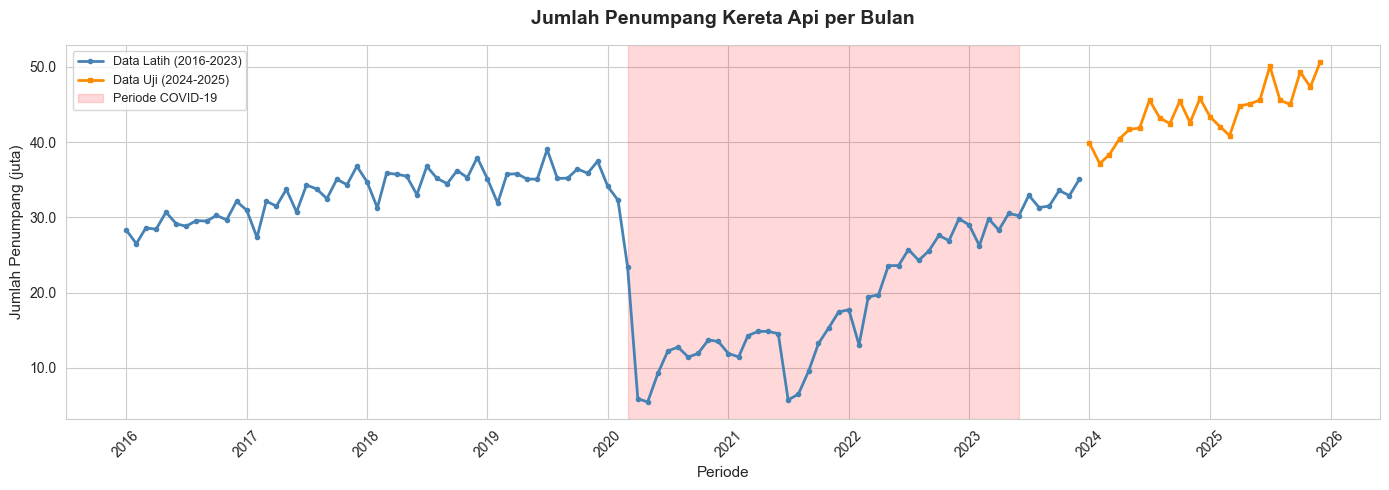

In [225]:
# 5.2 Visualisasi Time Series dengan Penanda Periode COVID-19
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y_train.index, y_train.values, color='steelblue',
        linewidth=2, marker='o', markersize=3, label=f'Data Latih ({df_train.index[0].year}-{df_train.index[-1].year})')
ax.plot(y_test.index, y_test.values, color='darkorange',
        linewidth=2, marker='s', markersize=3, label=f'Data Uji ({df_test.index[0].year}-{df_test.index[-1].year})')

covid_start = pd.Timestamp('2020-03-01')
covid_end   = pd.Timestamp('2023-06-01')
ax.axvspan(covid_start, covid_end, alpha=0.15, color='red', label='Periode COVID-19')
ax.set_title('Jumlah Penumpang Kereta Api per Bulan', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Periode', fontsize=11)
ax.set_ylabel('Jumlah Penumpang (juta)', fontsize=11)
ax.legend(fontsize=9)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.1f}'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator())
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('plot_01_data_timeseries.png', bbox_inches='tight', dpi=120)
plt.show()

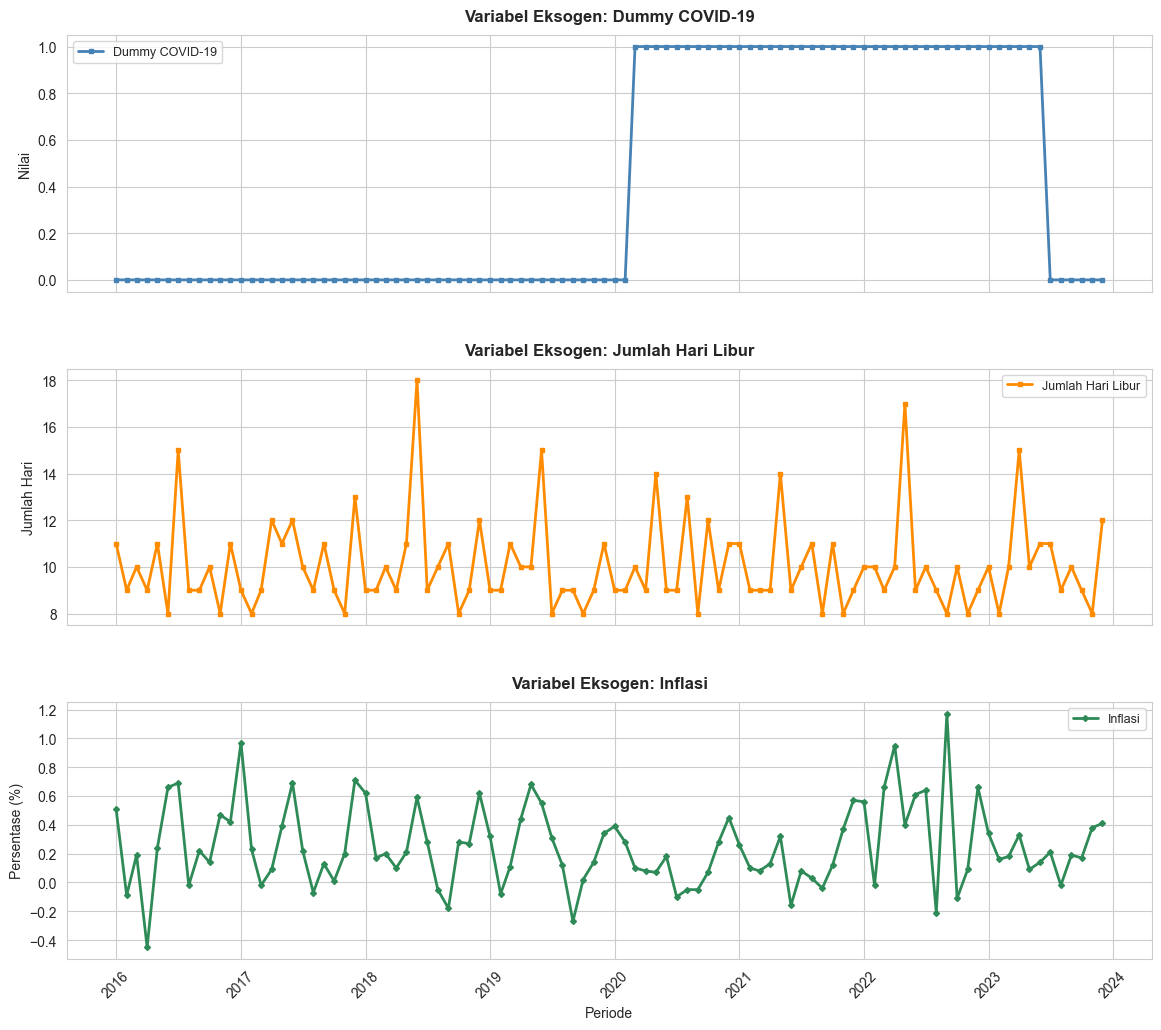

In [226]:
# 5.3 Visualisasi Variabel Eksogen
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True, gridspec_kw={'hspace': 0.3})
axes[0].plot(X_train.index, X_train['Dummy_Covid'], color='steelblue', linewidth=2, marker='s', markersize=3, label='Dummy COVID-19')
axes[0].set_title('Variabel Eksogen: Dummy COVID-19', fontsize=12, fontweight='bold', pad=10)
axes[0].set_ylabel('Nilai', fontsize=10)
axes[0].legend(fontsize=9)

axes[1].plot(X_train.index, X_train['Hari_Libur'], color='darkorange', linewidth=2, marker='s', markersize=3, label='Jumlah Hari Libur')
axes[1].set_title('Variabel Eksogen: Jumlah Hari Libur', fontsize=12, fontweight='bold', pad=10)
axes[1].set_ylabel('Jumlah Hari', fontsize=10)
axes[1].legend(fontsize=9)

axes[2].plot(X_train.index, X_train['Inflasi'], color='seagreen', linewidth=2, marker='D', markersize=3, label='Inflasi')
axes[2].set_title('Variabel Eksogen: Inflasi', fontsize=12, fontweight='bold', pad=10)
axes[2].set_xlabel('Periode', fontsize=10)
axes[2].set_ylabel('Persentase (%)', fontsize=10)
axes[2].legend(fontsize=9)
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[2].xaxis.set_major_locator(mdates.YearLocator())
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('plot_02_exogenous_variables.png', bbox_inches='tight', dpi=120)
plt.show()

Matriks Korelasi (Data Latih):
                Penumpang  Dummy_Covid  Inflasi  Hari_Libur  Penumpang_juta
Penumpang            1.00        -0.81     0.15       -0.02            1.00
Dummy_Covid         -0.81         1.00    -0.03        0.03           -0.81
Inflasi              0.15        -0.03     1.00        0.19            0.15
Hari_Libur          -0.02         0.03     0.19        1.00           -0.02
Penumpang_juta       1.00        -0.81     0.15       -0.02            1.00


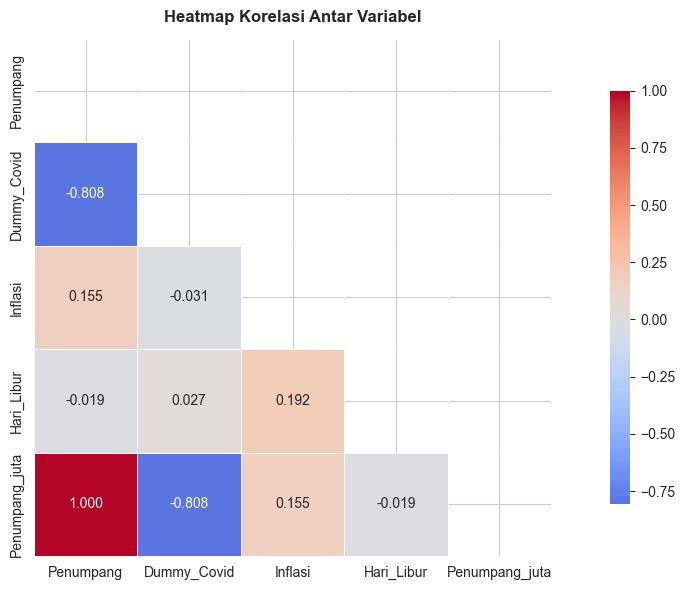

In [227]:
# 5.4 Korelasi Variabel Eksogen
corr_matrix = df_train.corr()
print("Matriks Korelasi (Data Latih):")
print(corr_matrix.round(3))

fig, ax = plt.subplots(figsize=(12, 6))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm',
            center=0, square=True, mask=mask, ax=ax,
            linewidths=0.5, cbar_kws={'shrink': 0.8})
ax.set_title('Heatmap Korelasi Antar Variabel', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('plot_04_korelasi.png', bbox_inches='tight', dpi=120)
plt.show()

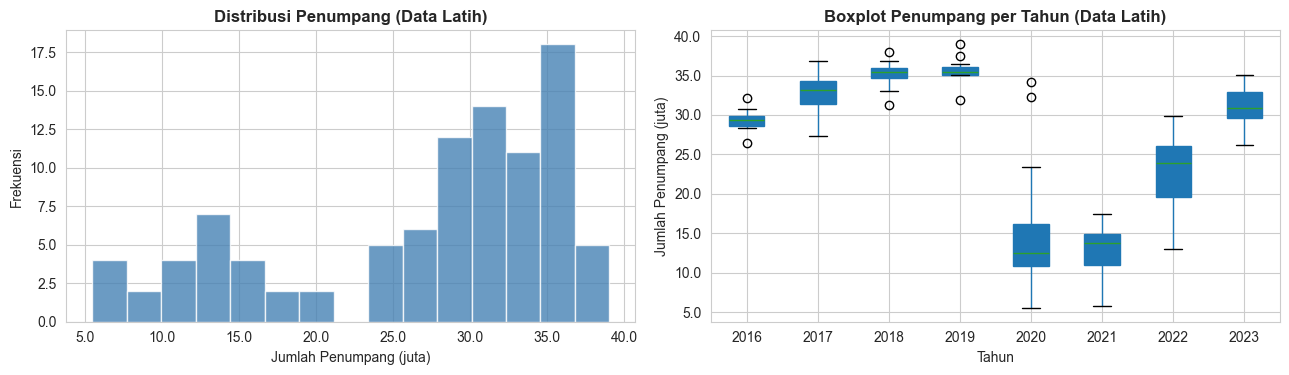

In [228]:
# 5.5 Histogram dan Boxplot Variabel Target
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(y_train.values, bins=15, color='steelblue', edgecolor='white', alpha=0.8)
axes[0].set_title('Distribusi Penumpang (Data Latih)', fontweight='bold')
axes[0].set_xlabel('Jumlah Penumpang (juta)')
axes[0].set_ylabel('Frekuensi')
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.1f}'))

df_train_copy = df_train.copy()
df_train_copy['Tahun'] = df_train_copy.index.year
df_train_copy.boxplot(column=TARGET_COL, by='Tahun', ax=axes[1], patch_artist=True)
axes[1].set_title('Boxplot Penumpang per Tahun (Data Latih)', fontweight='bold')
axes[1].set_xlabel('Tahun')
axes[1].set_ylabel('Jumlah Penumpang (juta)')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.1f}'))
plt.suptitle('')
plt.tight_layout()
plt.savefig('plot_03_distribusi.png', bbox_inches='tight', dpi=120)
plt.show()

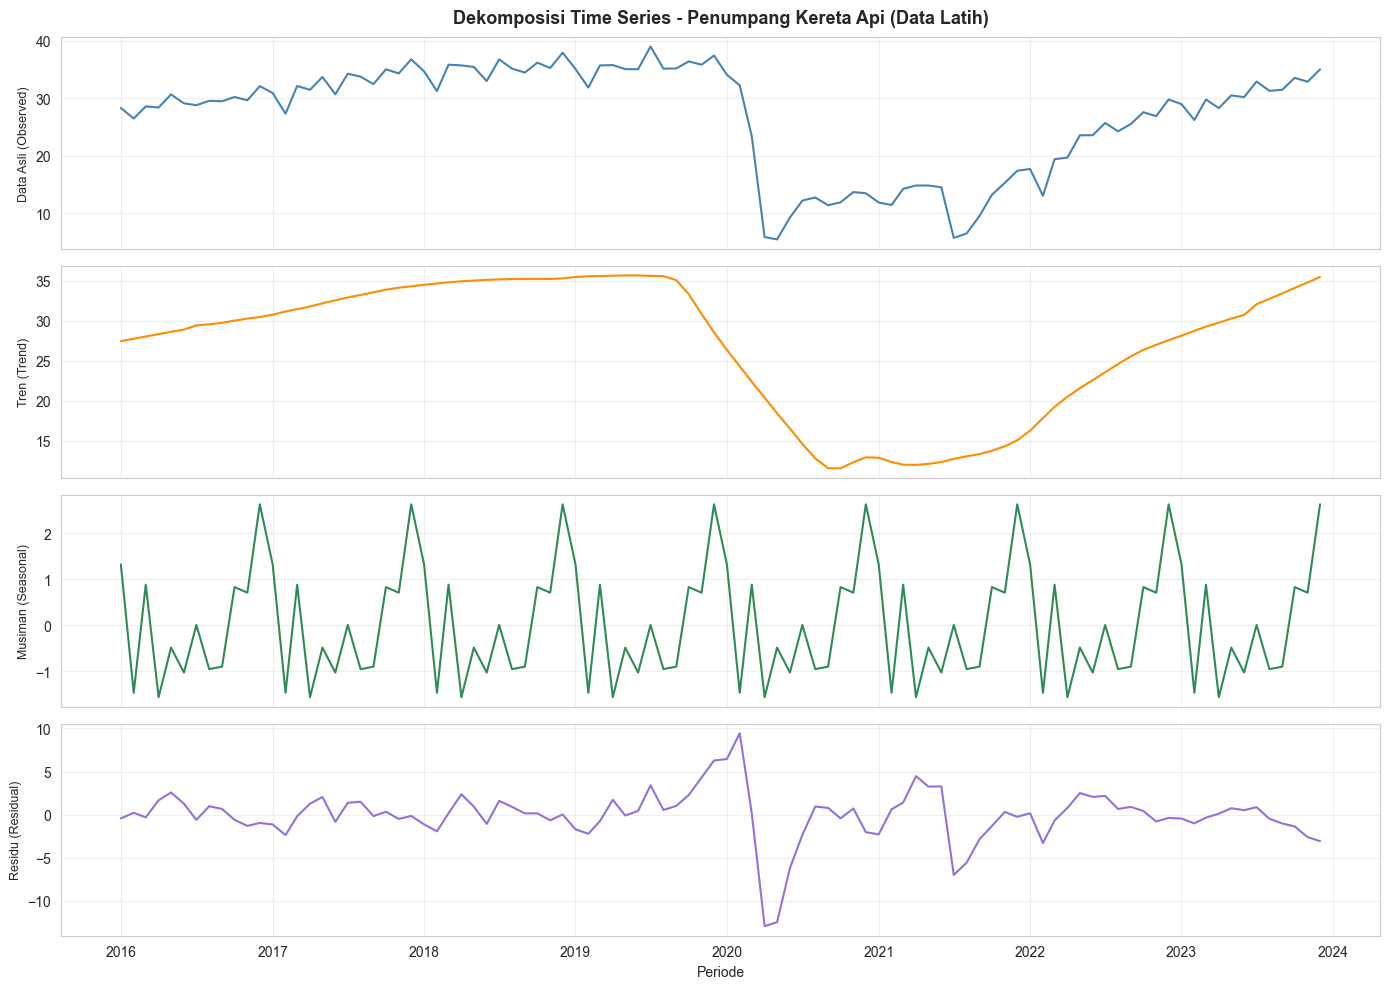

In [229]:
# 5.6 Dekomposisi Time Series
decomp = seasonal_decompose(y_train, model='additive', period=12, extrapolate_trend='freq')
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
components = {
    'Data Asli (Observed)': decomp.observed,
    'Tren (Trend)': decomp.trend,
    'Musiman (Seasonal)': decomp.seasonal,
    'Residu (Residual)': decomp.resid,
}
colors = ['steelblue', 'darkorange', 'seagreen', 'mediumpurple']

for ax, (title, data), color in zip(axes, components.items(), colors):
    ax.plot(data, color=color, linewidth=1.5)
    ax.set_ylabel(title, fontsize=9)
    ax.grid(True, alpha=0.3)

axes[0].set_title('Dekomposisi Time Series - Penumpang Kereta Api (Data Latih)', fontsize=13, fontweight='bold', pad=10)
axes[-1].set_xlabel('Periode', fontsize=10)
plt.tight_layout()
plt.savefig('plot_05_dekomposisi.png', bbox_inches='tight', dpi=120)
plt.show()

### **6. UJI STASIONERITAS DAN TRANSFORMASI DATA**

In [230]:
# Langkah 1: Uji stasioneritas varians dengan Box-Cox
data_boxcox, lambda_value = boxcox(y_train)

print(f"Nilai lambda Box-Cox: {lambda_value:.4f}")

if abs(lambda_value - 1) < 0.1:
    perlu_transformasi = False
    print("Lambda mendekati 1 -> data sudah stasioner dalam varians, transformasi TIDAK diperlukan.")
else:
    perlu_transformasi = True
    print("Lambda menjauhi 1 -> data BELUM stasioner dalam varians, transformasi Box-Cox diperlukan")

# Definisi fungsi transformasi
def forward_boxcox(data_asli, lam):
    data_asli = np.asarray(data_asli, dtype=float)
    if abs(lam) < 1e-8:
        return np.log(data_asli)
    return (np.power(data_asli, lam) - 1) / lam

def inverse_boxcox_custom(data_transformed, lam):
    data_transformed = np.asarray(data_transformed, dtype=float)
    if abs(lam) < 1e-8:
        return np.exp(data_transformed)
    return inv_boxcox(data_transformed, lam)

if perlu_transformasi:
    y_train_model = pd.Series(forward_boxcox(y_train.values, lambda_value), index=y_train.index)
else:
    y_train_model = y_train.copy()

print(f"\n'y_train_model' didefinisikan (skala hasil transformasi Box-Cox).")
print("Seri ini dipakai secara konsisten di seluruh tahap berikutnya.")

Nilai lambda Box-Cox: 1.9317
Lambda menjauhi 1 -> data BELUM stasioner dalam varians, transformasi Box-Cox diperlukan

'y_train_model' didefinisikan (skala hasil transformasi Box-Cox).
Seri ini dipakai secara konsisten di seluruh tahap berikutnya.


In [231]:
# Langkah 2: Uji stasioneritas rata-rata dengan ADF
def uji_adf(series, nama, d=0):
    hasil = adfuller(series.dropna())
    print(f"--- Uji ADF: {nama} ---")
    print(f"ADF Statistic : {hasil[0]:.4f}")
    print(f"p-value       : {hasil[1]:.4f}")
    print(f"Kesimpulan    : {'STASIONER' if hasil[1] < 0.05 else 'BELUM STASIONER (perlu differencing)'}")
    print()
    return hasil[1] < 0.05

# Uji stasioneritas data asli
stasioner = uji_adf(y_train_model, 'Penumpang (y_train_model)')

# Jika tidak stasioner, lakukan differencing
if not stasioner:
    d_optimal = 0
    series_diff = y_train_model.copy()
    
    while True:
        d_optimal += 1
        series_diff = series_diff.diff().dropna()
        if uji_adf(series_diff, f'Penumpang (d={d_optimal})', d_optimal):
            break
        if d_optimal >= 2:
            break
else:
    d_optimal = 0

print(f"Orde differencing (d) yang digunakan: {d_optimal}")

--- Uji ADF: Penumpang (y_train_model) ---
ADF Statistic : -1.9304
p-value       : 0.3179
Kesimpulan    : BELUM STASIONER (perlu differencing)

--- Uji ADF: Penumpang (d=1) ---
ADF Statistic : -2.2561
p-value       : 0.1865
Kesimpulan    : BELUM STASIONER (perlu differencing)

--- Uji ADF: Penumpang (d=2) ---
ADF Statistic : -4.0815
p-value       : 0.0010
Kesimpulan    : STASIONER

Orde differencing (d) yang digunakan: 2


### **7. IDENTIFIKASI MODEL (ACF DAN PACF)**

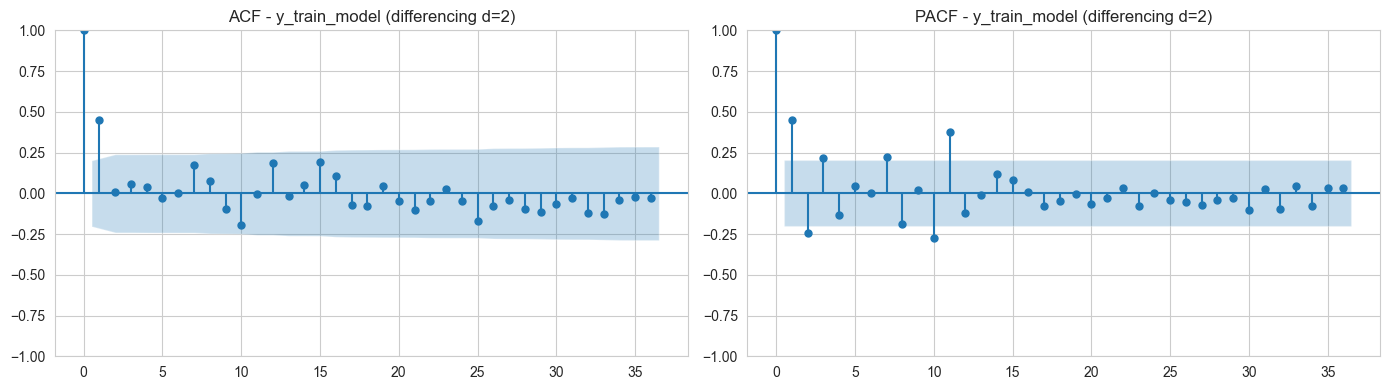

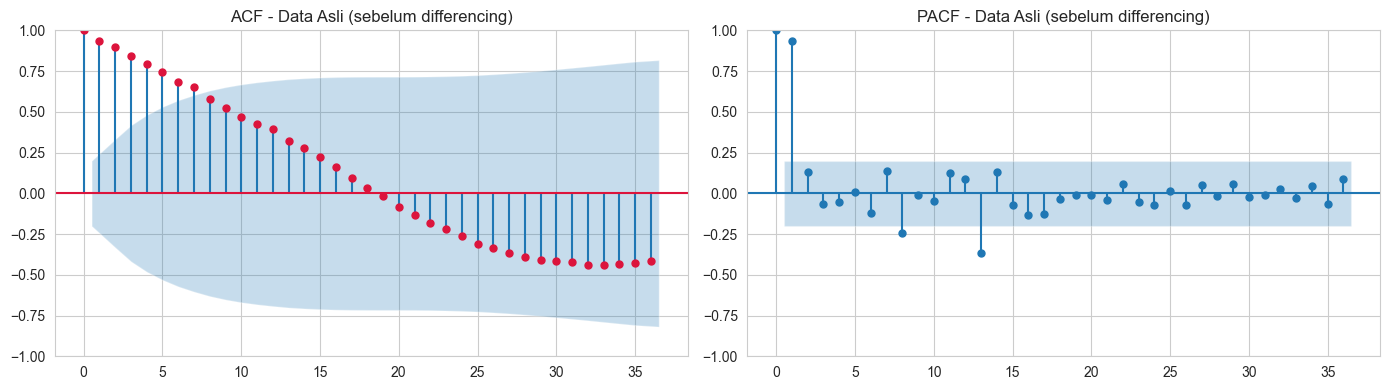

In [232]:
# Plot ACF dan PACF pada data stasioner
series_stasioner = y_train_model.diff(d_optimal).dropna() if d_optimal > 0 else y_train_model
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(series_stasioner, lags=36, ax=axes[0])
axes[0].set_title(f'ACF - y_train_model (differencing d={d_optimal})')
plot_pacf(series_stasioner, lags=36, ax=axes[1], method='ywm')
axes[1].set_title(f'PACF - y_train_model (differencing d={d_optimal})')
plt.tight_layout()
plt.savefig('acf_pacf.png', dpi=150)
plt.show()

# Plot ACF dan PACF data asli (sebelum differencing)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(y_train_model, lags=36, ax=axes[0], color='crimson')
axes[0].set_title('ACF - Data Asli (sebelum differencing)')
plot_pacf(y_train_model, lags=36, ax=axes[1], method='ywm',)
axes[1].set_title('PACF - Data Asli (sebelum differencing)')
plt.tight_layout()
plt.savefig('acf_pacf_asli.png', dpi=150)
plt.show()

### **8. ESTIMASI PARAMETER**

In [233]:
# Grid search untuk model ARIMAX
p_range = range(0, 2)
q_range = range(0, 2)

hasil_arimax = []
for p, q in itertools.product(p_range, q_range):
    try:
        model = SARIMAX(
            y_train_model, exog=X_train,
            order=(p, d_optimal, q),
            enforce_stationarity=False,
            enforce_invertibility=False)
        hasil_fit = model.fit(disp=False, maxiter=200)
        hasil_arimax.append({'p': p, 'd': d_optimal, 'q': q, 'AIC': hasil_fit.aic})
    except Exception:
        pass

df_arimax = pd.DataFrame(hasil_arimax).sort_values('AIC').reset_index(drop=True)
print("Kandidat Model ARIMAX dengan AIC terkecil:")
df_arimax.head(10)

Kandidat Model ARIMAX dengan AIC terkecil:


,p,d,q,AIC
0,1,2,1,1008.81
1,0,2,1,1013.69
2,1,2,0,1061.98
3,0,2,0,1102.67


In [234]:
# Menentukan orde differencing musiman (D)
s = 12

series_D0 = y_train_model.diff(d_optimal).dropna() if d_optimal > 0 else y_train_model.copy()
acf_D0 = acf(series_D0, nlags=s, fft=True)[s]

series_D1 = series_D0.diff(s).dropna()
acf_D1 = acf(series_D1, nlags=s, fft=True)[s]

print(f"Autokorelasi pada lag musiman (lag={s}) tanpa differencing musiman (D=0): {acf_D0:.4f}")
print(f"Autokorelasi pada lag musiman (lag={s}) dengan differencing musiman (D=1): {acf_D1:.4f}")

D_musiman = 1 if abs(acf_D1) < abs(acf_D0) else 0
print(f"Orde differencing musiman (D) yang dipilih: D = {D_musiman}")

Autokorelasi pada lag musiman (lag=12) tanpa differencing musiman (D=0): 0.1838
Autokorelasi pada lag musiman (lag=12) dengan differencing musiman (D=1): -0.3783
Orde differencing musiman (D) yang dipilih: D = 0


In [235]:
# Grid search untuk model SARIMAX
p_range_s = range(0, 2)
q_range_s = range(0, 2)
P_range = range(0, 2)
Q_range = range(0, 2)

hasil_sarimax = []
for p, q, P, Q in itertools.product(p_range_s, q_range_s, P_range, Q_range):
    try:
        model = SARIMAX(y_train_model, exog=X_train, order=(p, d_optimal, q),
                        seasonal_order=(P, D_musiman, Q, s),
                        enforce_stationarity=False, enforce_invertibility=False)
        hasil_fit = model.fit(disp=False, maxiter=200)
        hasil_sarimax.append({'p': p, 'd': d_optimal, 'q': q,
                              'P': P, 'D': D_musiman, 'Q': Q, 's': s,
                              'AIC': hasil_fit.aic})
    except Exception:
        pass

df_sarimax = pd.DataFrame(hasil_sarimax).sort_values('AIC').reset_index(drop=True)
print(f"Jumlah kombinasi berhasil diestimasi: {len(df_sarimax)}")
print("\nKandidat Model SARIMAX dengan AIC terkecil:")
df_sarimax.head(10)

Jumlah kombinasi berhasil diestimasi: 16

Kandidat Model SARIMAX dengan AIC terkecil:


,p,d,q,P,D,Q,s,AIC
0,0,2,1,1,0,1,12,857.71
1,1,2,1,1,0,1,12,859.67
2,0,2,1,0,0,1,12,871.61
3,1,2,1,0,0,1,12,872.08
4,1,2,1,1,0,0,12,875.51
5,0,2,1,1,0,0,12,889.03
6,1,2,0,1,0,1,12,896.40
7,1,2,0,1,0,0,12,902.34
8,1,2,0,0,0,1,12,910.80
9,0,2,0,1,0,1,12,912.75


In [236]:
# Model terbaik berdasarkan AIC
order_arimax_terbaik = tuple(int(x) for x in df_arimax.iloc[0][['p', 'd', 'q']])

baris_sarimax_terbaik = df_sarimax.iloc[0]
order_sarimax_terbaik = tuple(int(x) for x in baris_sarimax_terbaik[['p', 'd', 'q']])
seasonal_order_terbaik = tuple(int(x) for x in baris_sarimax_terbaik[['P', 'D', 'Q', 's']])

print(f"Model ARIMAX terbaik berdasarkan AIC : order={order_arimax_terbaik}  (AIC={df_arimax.iloc[0]['AIC']:.2f})")
print(f"Model SARIMAX terbaik berdasarkan AIC: order={order_sarimax_terbaik}, seasonal_order={seasonal_order_terbaik}  (AIC={baris_sarimax_terbaik['AIC']:.2f})")

Model ARIMAX terbaik berdasarkan AIC : order=(1, 2, 1)  (AIC=1008.81)
Model SARIMAX terbaik berdasarkan AIC: order=(0, 2, 1), seasonal_order=(1, 0, 1, 12)  (AIC=857.71)


### **9. ESTIMASI PARAMETER MODEL TERBAIK**

In [237]:
# Estimasi model ARIMAX terbaik
model_arimax = SARIMAX(y_train_model, exog=X_train, order=order_arimax_terbaik,
                       enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)

print("=== RINGKASAN MODEL ARIMAX ===")
print(model_arimax.summary())

=== RINGKASAN MODEL ARIMAX ===
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                   96
Model:               SARIMAX(1, 2, 1)   Log Likelihood                -499.197
Date:                Wed, 15 Jul 2026   AIC                           1010.394
Time:                        01:36:54   BIC                           1025.525
Sample:                    01-01-2016   HQIC                          1016.501
                         - 12-01-2023                                         
Covariance Type:                  opg                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Dummy_Covid  -121.0243     31.676     -3.821      0.000    -183.108     -58.941
Inflasi        35.7523     20.346      1.757      0.079      -4.126      75.631
Hari_Libur     -0

In [238]:
# Estimasi model SARIMAX terbaik
model_sarimax = SARIMAX(y_train_model, exog=X_train, order=order_sarimax_terbaik,
                        seasonal_order=seasonal_order_terbaik,
                        enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)

print("=== RINGKASAN MODEL SARIMAX ===")
print(model_sarimax.summary())

=== RINGKASAN MODEL SARIMAX ===
                                     SARIMAX Results                                      
Dep. Variable:                                  y   No. Observations:                   96
Model:             SARIMAX(0, 2, 1)x(1, 0, 1, 12)   Log Likelihood                -423.015
Date:                            Wed, 15 Jul 2026   AIC                            860.030
Time:                                    01:36:55   BIC                            876.704
Sample:                                01-01-2016   HQIC                           866.715
                                     - 12-01-2023                                         
Covariance Type:                              opg                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Dummy_Covid   -96.0447     17.611     -5.454      0.000    -130.563     -61.527


### **10. UJI MULTIKOLINEARITAS**

In [239]:
# Uji VIF untuk variabel eksogen
X_vif = X_train.copy()
X_vif.insert(0, 'const', 1)

vif_hasil = pd.DataFrame()
vif_hasil['Variabel'] = X_vif.columns
vif_hasil['VIF'] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
vif_hasil = vif_hasil[vif_hasil['Variabel'] != 'const'].reset_index(drop=True)

print(vif_hasil)
for _, row in vif_hasil.iterrows():
    status = "MULTIKOLINEARITAS SERIUS" if row['VIF'] > 10 else "Aman"
    print(f"{row['Variabel']:15s} VIF = {row['VIF']:.3f}  -> {status}")

      Variabel  VIF
0  Dummy_Covid 1.00
1      Inflasi 1.04
2   Hari_Libur 1.04
Dummy_Covid     VIF = 1.002  -> Aman
Inflasi         VIF = 1.040  -> Aman
Hari_Libur      VIF = 1.040  -> Aman


### **11. UJI DIAGNOSTIK RESIDUAL**

In [240]:
def uji_diagnostik_residual(model_fit, nama_model):
    residual = model_fit.resid
    print(f"========== UJI DIAGNOSTIK RESIDUAL: {nama_model} ==========\n")

    # Uji Ljung-Box untuk independensi residual
    lb = acorr_ljungbox(residual, lags=[6, 12, 24], return_df=True)
    print("1. Uji Independensi (Ljung-Box):")
    print(lb)
    print("   Kesimpulan:", "Residual white noise (independen)" if (lb['lb_pvalue'] > 0.05).all() else "Masih terdapat autokorelasi pada residual")
    print()

    # Uji Jarque-Bera untuk normalitas residual
    jb_stat, jb_pval = jarque_bera(residual)
    print(f"2. Uji Normalitas (Jarque-Bera): statistic={jb_stat:.4f}, p-value={jb_pval:.4f}")
    print("   Kesimpulan:", "Residual berdistribusi normal" if jb_pval > 0.05 else "Residual tidak berdistribusi normal")
    print()

    # Uji ARCH-LM untuk homoskedastisitas
    arch_stat, arch_pval, _, _ = het_arch(residual)
    print(f"3. Uji Homoskedastisitas (ARCH-LM): statistic={arch_stat:.4f}, p-value={arch_pval:.4f}")
    print("   Kesimpulan:", "Tidak ada efek ARCH (homoskedastis)" if arch_pval > 0.05 else "Terdapat heteroskedastisitas bersyarat (ARCH)")
    print("\n")

    return residual

# Uji diagnostik ARIMAX
residual_arimax = uji_diagnostik_residual(model_arimax, "ARIMAX")

# Uji diagnostik SARIMAX
residual_sarimax = uji_diagnostik_residual(model_sarimax, "SARIMAX")

========== UJI DIAGNOSTIK RESIDUAL: ARIMAX ==========

1. Uji Independensi (Ljung-Box):
    lb_stat  lb_pvalue
6      6.72       0.35
12    20.38       0.06
24    40.07       0.02
   Kesimpulan: Masih terdapat autokorelasi pada residual

2. Uji Normalitas (Jarque-Bera): statistic=139.2214, p-value=0.0000
   Kesimpulan: Residual tidak berdistribusi normal

3. Uji Homoskedastisitas (ARCH-LM): statistic=4.6705, p-value=0.9121
   Kesimpulan: Tidak ada efek ARCH (homoskedastis)


========== UJI DIAGNOSTIK RESIDUAL: SARIMAX ==========

1. Uji Independensi (Ljung-Box):
    lb_stat  lb_pvalue
6     18.55       0.00
12    26.79       0.01
24    33.12       0.10
   Kesimpulan: Masih terdapat autokorelasi pada residual

2. Uji Normalitas (Jarque-Bera): statistic=327.3154, p-value=0.0000
   Kesimpulan: Residual tidak berdistribusi normal

3. Uji Homoskedastisitas (ARCH-LM): statistic=14.3003, p-value=0.1597
   Kesimpulan: Tidak ada efek ARCH (homoskedastis)




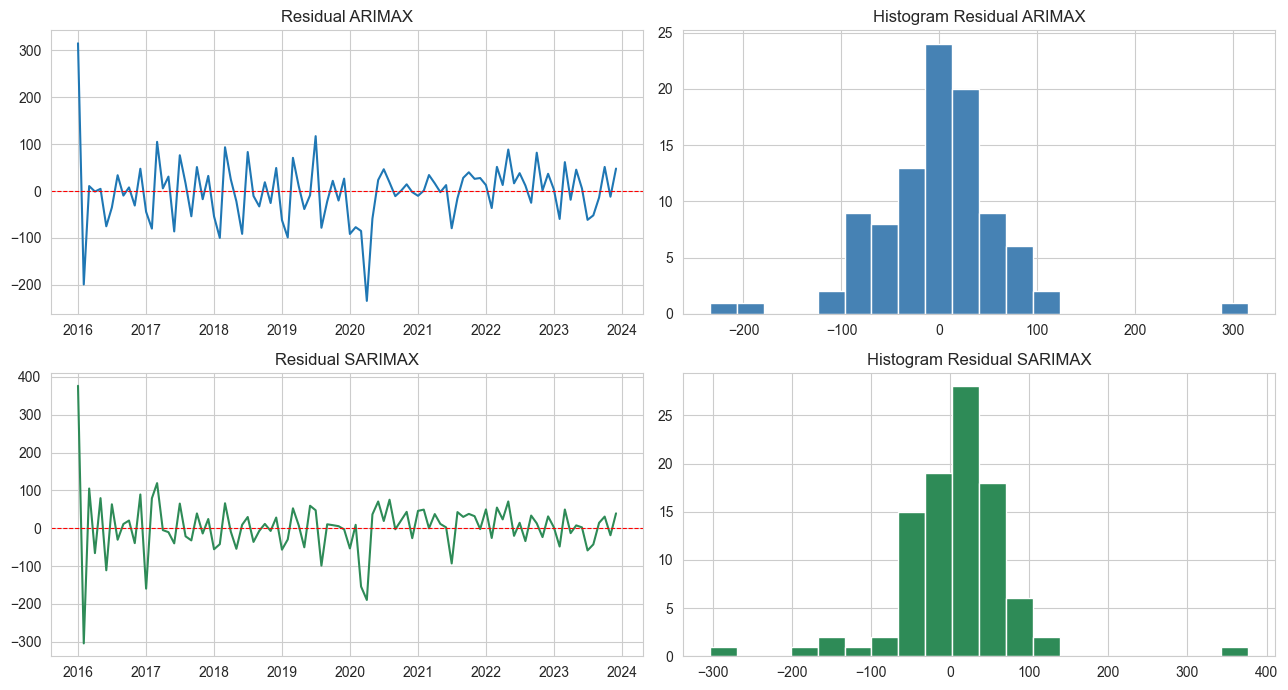

In [241]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))

axes[0,0].plot(residual_arimax); axes[0,0].set_title('Residual ARIMAX'); axes[0,0].axhline(0, color='red', linestyle='--', linewidth=0.8)
axes[0,1].hist(residual_arimax, bins=20, color='steelblue'); axes[0,1].set_title('Histogram Residual ARIMAX')
axes[1,0].plot(residual_sarimax, color='seagreen'); axes[1,0].set_title('Residual SARIMAX'); axes[1,0].axhline(0, color='red', linestyle='--', linewidth=0.8)
axes[1,1].hist(residual_sarimax, bins=20, color='seagreen'); axes[1,1].set_title('Histogram Residual SARIMAX')

plt.tight_layout()
plt.savefig('diagnostik_residual.png', dpi=150)
plt.show()

### **12. UJI SIGNIFIKANSI PARAMETER**

In [242]:
def tampilkan_signifikansi_eksogen(model_fit, nama_model):
    print(f"========== SIGNIFIKANSI PARAMETER EKSOGEN: {nama_model} ==========")
    tabel_eksogen = pd.DataFrame({
        'Coef.': model_fit.params[EXOGENOUS_COLS],
        'Std.Err.': model_fit.bse[EXOGENOUS_COLS],
        'z': model_fit.tvalues[EXOGENOUS_COLS],
        'P>|z|': model_fit.pvalues[EXOGENOUS_COLS],
    })
    print(tabel_eksogen)
    print()
    for var in EXOGENOUS_COLS:
        pval = model_fit.pvalues[var]
        kesimpulan = "BERPENGARUH SIGNIFIKAN (tolak H0)" if pval < 0.05 else "tidak berpengaruh signifikan (gagal tolak H0)"
        print(f"  - {var:15s} p-value = {pval:.4f}  -> {kesimpulan}")
    print("\n")

tampilkan_signifikansi_eksogen(model_arimax, "ARIMAX")
tampilkan_signifikansi_eksogen(model_sarimax, "SARIMAX")

========== SIGNIFIKANSI PARAMETER EKSOGEN: ARIMAX ==========
              Coef.  Std.Err.     z  P>|z|
Dummy_Covid -121.02     31.68 -3.82   0.00
Inflasi       35.75     20.35  1.76   0.08
Hari_Libur    -0.21      2.15 -0.10   0.92

  - Dummy_Covid     p-value = 0.0001  -> BERPENGARUH SIGNIFIKAN (tolak H0)
  - Inflasi         p-value = 0.0789  -> tidak berpengaruh signifikan (gagal tolak H0)
  - Hari_Libur      p-value = 0.9206  -> tidak berpengaruh signifikan (gagal tolak H0)


========== SIGNIFIKANSI PARAMETER EKSOGEN: SARIMAX ==========
             Coef.  Std.Err.     z  P>|z|
Dummy_Covid -96.04     17.61 -5.45   0.00
Inflasi      -8.39     18.27 -0.46   0.65
Hari_Libur   -3.78      1.95 -1.94   0.05

  - Dummy_Covid     p-value = 0.0000  -> BERPENGARUH SIGNIFIKAN (tolak H0)
  - Inflasi         p-value = 0.6463  -> tidak berpengaruh signifikan (gagal tolak H0)
  - Hari_Libur      p-value = 0.0519  -> tidak berpengaruh signifikan (gagal tolak H0)




In [243]:
print("=== AIC MASING-MASING MODEL (data latih) ===")
print(f"AIC ARIMAX  : {model_arimax.aic:.2f}   -> order={order_arimax_terbaik}")
print(f"AIC SARIMAX : {model_sarimax.aic:.2f}   -> order={order_sarimax_terbaik}, seasonal_order={seasonal_order_terbaik}")
print("\nCatatan: AIC lebih kecil TIDAK otomatis berarti model tersebut akan meramal lebih baik pada")
print("data uji. Model dengan lebih banyak parameter musiman selalu bisa mencapai kecocokan yang")
print("lebih baik pada data latih (AIC/log-likelihood membaik), tanpa berarti generalisasinya lebih")
print("baik. Keputusan model terbaik ditentukan dari performa pada data uji.")

=== AIC MASING-MASING MODEL (data latih) ===
AIC ARIMAX  : 1010.39   -> order=(1, 2, 1)
AIC SARIMAX : 860.03   -> order=(0, 2, 1), seasonal_order=(1, 0, 1, 12)

Catatan: AIC lebih kecil TIDAK otomatis berarti model tersebut akan meramal lebih baik pada
data uji. Model dengan lebih banyak parameter musiman selalu bisa mencapai kecocokan yang
lebih baik pada data latih (AIC/log-likelihood membaik), tanpa berarti generalisasinya lebih
baik. Keputusan model terbaik ditentukan dari performa pada data uji.


### **14. EVALUASI DAN PEMILIHAN MODEL TERBAIK**

In [244]:
def evaluasi_model(model_fit, X_test, y_test_asli, nama_model, lam, transformasi_diterapkan):
    forecast_obj = model_fit.get_forecast(steps=len(y_test_asli), exog=X_test)
    pred_transformed = forecast_obj.predicted_mean
    ci_transformed = forecast_obj.conf_int()

    if transformasi_diterapkan:
        pred = pd.Series(inverse_boxcox_custom(pred_transformed.values, lam), index=pred_transformed.index)
        ci = pd.DataFrame(
            np.column_stack([
                inverse_boxcox_custom(ci_transformed.iloc[:, 0].values, lam),
                inverse_boxcox_custom(ci_transformed.iloc[:, 1].values, lam)
            ]),
            index=ci_transformed.index, columns=ci_transformed.columns
        )
    else:
        pred = pred_transformed
        ci = ci_transformed

    mape = mean_absolute_percentage_error(y_test_asli, pred) * 100
    rmse = np.sqrt(mean_squared_error(y_test_asli, pred))
    mae = mean_absolute_error(y_test_asli, pred)

    print(f"{nama_model:10s} -> MAPE: {mape:6.2f}%   RMSE: {rmse:,.2f}   MAE: {mae:,.2f}")
    return pred, ci, mape, rmse, mae

# Evaluasi kedua model pada data uji
pred_arimax, ci_arimax, mape_arimax, rmse_arimax, mae_arimax = evaluasi_model(
    model_arimax, X_test, y_test, "ARIMAX", lambda_value, perlu_transformasi)
pred_sarimax, ci_sarimax, mape_sarimax, rmse_sarimax, mae_sarimax = evaluasi_model(
    model_sarimax, X_test, y_test, "SARIMAX", lambda_value, perlu_transformasi)

print()
tabel_perbandingan = pd.DataFrame({
    'Model': ['ARIMAX', 'SARIMAX'],
    'AIC (data latih)': [model_arimax.aic, model_sarimax.aic],
    'MAPE % (data uji)': [mape_arimax, mape_sarimax],
    'RMSE juta (data uji)': [rmse_arimax, rmse_sarimax],
    'MAE juta (data uji)': [mae_arimax, mae_sarimax],
})
print(tabel_perbandingan)

# Pilih model terbaik berdasarkan RMSE pada data uji
model_terbaik = 'ARIMAX' if rmse_arimax < rmse_sarimax else 'SARIMAX'
print(f"\n>>> Model dengan performa terbaik pada DATA UJI: {model_terbaik} <<<")

ARIMAX     -> MAPE:  19.51%   RMSE: 9.28   MAE: 8.75
SARIMAX    -> MAPE:  15.56%   RMSE: 7.24   MAE: 6.94

     Model  AIC (data latih)  MAPE % (data uji)  RMSE juta (data uji)  \
0   ARIMAX           1010.39              19.51                  9.28   
1  SARIMAX            860.03              15.56                  7.24   

   MAE juta (data uji)  
0                 8.75  
1                 6.94  

>>> Model dengan performa terbaik pada DATA UJI: SARIMAX <<<


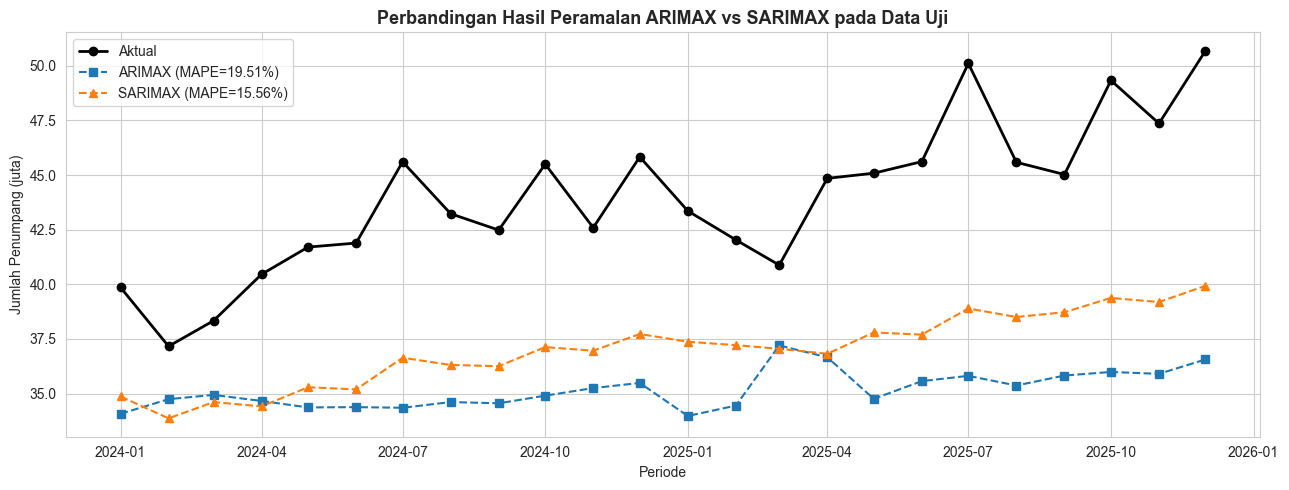

In [245]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(y_test.index, y_test.values, label='Aktual', color='black', marker='o', linewidth=2)
ax.plot(y_test.index, pred_arimax.values, label=f'ARIMAX (MAPE={mape_arimax:.2f}%)', linestyle='--', marker='s')
ax.plot(y_test.index, pred_sarimax.values, label=f'SARIMAX (MAPE={mape_sarimax:.2f}%)', linestyle='--', marker='^')
ax.set_title('Perbandingan Hasil Peramalan ARIMAX vs SARIMAX pada Data Uji', fontsize=13, fontweight='bold')
ax.set_xlabel('Periode'); ax.set_ylabel('Jumlah Penumpang (juta)')
ax.legend()
plt.tight_layout()
plt.savefig('perbandingan_forecast_data_uji.png', dpi=150)
plt.show()

### **15. RE-ESTIMASI MODEL TERBAIK DENGAN SELURUH DATA**

In [246]:
# Gunakan seluruh data untuk estimasi final
y_full = df[TARGET_COL]
X_full = df[EXOGENOUS_COLS]

if perlu_transformasi:
    y_full_model = pd.Series(forward_boxcox(y_full.values, lambda_value), index=y_full.index)
else:
    y_full_model = y_full.copy()

if model_terbaik == 'ARIMAX':
    model_final = SARIMAX(y_full_model, exog=X_full, order=order_arimax_terbaik,
                          enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
else:
    model_final = SARIMAX(y_full_model, exog=X_full, order=order_sarimax_terbaik,
                          seasonal_order=seasonal_order_terbaik,
                          enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)

print(f"Model final yang digunakan untuk peramalan: {model_terbaik}")
print(f"Diestimasi pada {'data hasil transformasi Box-Cox' if perlu_transformasi else 'data skala asli'} dengan {len(y_full_model)} observasi.")
print(model_final.summary())

Model final yang digunakan untuk peramalan: SARIMAX
Diestimasi pada data hasil transformasi Box-Cox dengan 120 observasi.
                                     SARIMAX Results                                      
Dep. Variable:                                  y   No. Observations:                  120
Model:             SARIMAX(0, 2, 1)x(1, 0, 1, 12)   Log Likelihood                -567.097
Date:                            Wed, 15 Jul 2026   AIC                           1148.194
Time:                                    01:36:58   BIC                           1166.705
Sample:                                01-01-2016   HQIC                          1155.694
                                     - 12-01-2025                                         
Covariance Type:                              opg                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------

### **16. PERAMALAN 12 BULAN KE DEPAN**

In [247]:
# PROYEKSI INFLASI BERDASARKAN TAHUN SEBELUMNYA
inflasi_aktual = [-0.15, 0.68, 0.41, 0.13, 0.28, 0.44]
inflasi_jul_des_2025 = df['Inflasi'].loc['2025-07':'2025-12'].values.tolist()
inflasi_metode = inflasi_aktual + inflasi_jul_des_2025

inflasi_metode

[-0.15, 0.68, 0.41, 0.13, 0.28, 0.44, 0.3, -0.08, 0.21, 0.28, 0.17, 0.64]

In [248]:
tanggal_2026 = pd.date_range('2026-01-01', '2026-12-01', freq='MS')

# Nilai eksogen untuk tahun 2026 (asumsi berdasarkan tren historis dan proyeksi)
eksogen_2026 = pd.DataFrame({
    'Dummy_Covid': [0]*12,
    'Inflasi': [-0.15, 0.68, 0.41, 0.13, 0.28, 0.44, 0.3, -0.08, 0.21, 0.28, 0.17, 0.64],
    'Hari_Libur': [11, 10, 14, 9, 15, 10, 8, 12, 8, 9, 9, 10],
}, index=tanggal_2026)

print("Variabel eksogen untuk peramalan 2026:")
eksogen_2026

Variabel eksogen untuk peramalan 2026:


,Dummy_Covid,Inflasi,Hari_Libur
2026-01-01,0,-0.15,11
2026-02-01,0,0.68,10
2026-03-01,0,0.41,14
2026-04-01,0,0.13,9
2026-05-01,0,0.28,15
2026-06-01,0,0.44,10
2026-07-01,0,0.30,8
2026-08-01,0,-0.08,12
2026-09-01,0,0.21,8
2026-10-01,0,0.28,9


In [249]:
forecast_2026_raw = model_final.get_forecast(steps=12, exog=eksogen_2026)
pred_2026_transformed = forecast_2026_raw.predicted_mean
ci_2026_transformed = forecast_2026_raw.conf_int(alpha=0.05)

if perlu_transformasi:
    hasil_peramalan_juta = pd.Series(inverse_boxcox_custom(pred_2026_transformed.values, lambda_value), index=tanggal_2026)
    interval_keyakinan_juta = pd.DataFrame(
        np.column_stack([
            inverse_boxcox_custom(ci_2026_transformed.iloc[:, 0].values, lambda_value),
            inverse_boxcox_custom(ci_2026_transformed.iloc[:, 1].values, lambda_value)
        ]),
        index=tanggal_2026, columns=ci_2026_transformed.columns
    )
    print("Hasil peramalan dikembalikan ke skala asli via inverse Box-Cox.")
else:
    hasil_peramalan_juta = pred_2026_transformed
    interval_keyakinan_juta = ci_2026_transformed

hasil_peramalan = hasil_peramalan_juta * SKALA
interval_keyakinan = interval_keyakinan_juta * SKALA

tabel_hasil = pd.DataFrame({
    'Periode': tanggal_2026.strftime('%B %Y'),
    'Peramalan': hasil_peramalan.values.round(0),
    'Batas_Bawah_95%': interval_keyakinan.iloc[:, 0].values.round(0),
    'Batas_Atas_95%': interval_keyakinan.iloc[:, 1].values.round(0),
})

print(f"Hasil peramalan 2026 (model: {model_terbaik}), dalam satuan penumpang asli:")
tabel_hasil        

Hasil peramalan dikembalikan ke skala asli via inverse Box-Cox.
Hasil peramalan 2026 (model: SARIMAX), dalam satuan penumpang asli:


,Periode,Peramalan,Batas_Bawah_95%,Batas_Atas_95%
0,January 2026,50178803.00,47342975.00,52872584.00
1,February 2026,49039669.00,44849359.00,52920056.00
2,March 2026,48949811.00,43710378.00,53711963.00
3,April 2026,51980023.00,46199457.00,57215246.00
4,May 2026,51312102.00,44655520.00,57246269.00
5,June 2026,52292779.00,45036463.00,58712334.00
6,July 2026,54731244.00,47159415.00,61432291.00
7,August 2026,52138306.00,43479935.00,59624949.00
8,September 2026,52442797.00,43185923.00,60377786.00
9,October 2026,54604119.00,45147735.00,62732564.00


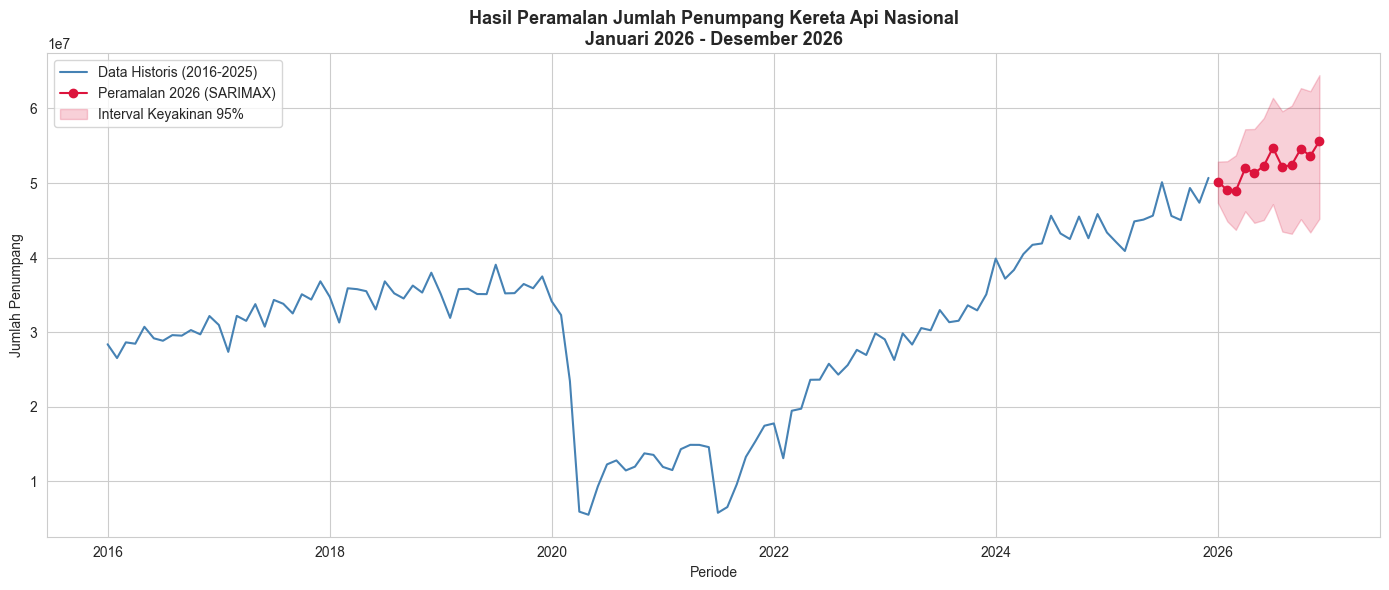

In [250]:
fig, ax = plt.subplots(figsize=(14, 6))

# Plot data historis
ax.plot(df.index, df['Penumpang'], label='Data Historis (2016-2025)', color='steelblue')
# Plot hasil peramalan
ax.plot(tanggal_2026, hasil_peramalan.values, label=f'Peramalan 2026 ({model_terbaik})', color='crimson', marker='o')
# Plot interval keyakinan
ax.fill_between(tanggal_2026, interval_keyakinan.iloc[:,0], interval_keyakinan.iloc[:,1],
                color='crimson', alpha=0.2, label='Interval Keyakinan 95%')

ax.set_title('Hasil Peramalan Jumlah Penumpang Kereta Api Nasional\nJanuari 2026 - Desember 2026',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Periode')
ax.set_ylabel('Jumlah Penumpang')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('hasil_peramalan_2026.png', dpi=150)
plt.show()